# sigker-nspdes: limit order book (FI-2010)

See `README.md` for method, choices and results.

In [1]:
import numpy as np
import torch
import wandb
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp
from torch.utils.data import DataLoader

from sigker_nspdes import (
    LOBDataset, SigKernel, signature_kernel_score, score_transform, resolve_sigma,
    build_generator, build_kernel, train, load_checkpoint, generate,
)

REAL_C, GEN_C = "#2a78d6", "#eb6834"   # real = blue, generated = orange throughout
FIELD_CMAP    = "RdBu_r"               # diverging around the z-score 0

In [2]:
CFG = dict(
    # --- data: FI-2010 LOB volumes (reference data/lob_neurips.npy) ---
    data_path  = "lob_neurips.npy",
    test_frac  = 0.1,       # last 10% of windows (chronological) held out; the paper trains on all
    dim_x      = 20,        # price levels: bid L10..L1 | ask L1..L10
    dim_t      = 32,        # events per window (paper: 30, reference: 32)

    # --- generator (Neural SPDE, fixed-point solver); paper App. B.5 / reference values ---
    noise_size   = 2,       # d_w = 2
    hidden_size  = 16,      # d_y in {16, 32}
    num_layers   = 1,
    modes_x      = 10,      # spatial modes in {10, 20}
    modes_t      = 20,      # temporal modes fixed to 20
    n_iter       = 4,       # Picard iterations
    noise_type   = "white", # "white" or "colored"
    readout_size = 128,
    norm         = "batch", # "batch" (reference BatchNorm, always batch stats) or "none"

    # --- signature kernel score ---
    kernel_type  = "rbf",   # RBF on spatial slices (paper "ID", reference "rbf_id")
    sigma        = "multiscale", # reference: 10.0. float, list, "median", or "multiscale" = median x (1/64, 1/8, 1)
    dyadic_order = 1,
    max_batch    = 128,     # reference: 32
    alpha        = 0.1,     # score is computed on alpha * cumsum_t(u), as the reference

    # --- training ---
    batch_size     = 128,   # reference: 32
    steps          = 3000,  # reference: 2000
    optimizer      = "Adam",
    lr             = 1e-3,
    weight_decay   = 0.0,
    grad_clip      = 10.0,
    swa_step_start = 1500,
    log_every      = 250,
    save_every     = 1000,
    seed           = 0,

    # --- run ---
    mode          = "train",  # "train" | "resume" | "eval"
    device        = "cuda" if torch.cuda.is_available() else "cpu",
    ckpt_dir      = "checkpoints/lob",
    wandb_log     = False,
    wandb_project = "sigker-nspde",
    wandb_entity  = None,
)

## Dataset

In [3]:
torch.manual_seed(CFG["seed"]); np.random.seed(CFG["seed"])

train_ds = LOBDataset(CFG["data_path"], CFG["dim_t"], split=(0.0, 1 - CFG["test_frac"]))
test_ds  = LOBDataset(CFG["data_path"], CFG["dim_t"], split=(1 - CFG["test_frac"], 1.0))
assert (train_ds.dim_t, train_ds.dim_x) == (CFG["dim_t"], CFG["dim_x"])

train_loader = DataLoader(train_ds, batch_size=CFG["batch_size"], shuffle=True, drop_last=True)
test_loader  = DataLoader(test_ds,  batch_size=CFG["batch_size"], shuffle=True, drop_last=True)
ts     = train_ds.ts.to(CFG["device"])
levels = np.arange(CFG["dim_x"])
LEVEL_TICKS = ([0, 9, 10, 19], ["bid L10", "bid L1", "ask L1", "ask L10"])

CFG["sigma"] = resolve_sigma(CFG["sigma"], train_ds.fields, CFG["alpha"])
print(f"train {tuple(train_ds.fields.shape)}  test {tuple(test_ds.fields.shape)}  RBF sigma = {np.round(CFG['sigma'], 3)}")

train (10192, 32, 20)  test (1133, 32, 20)  RBF sigma = [0.037 0.292 2.338]


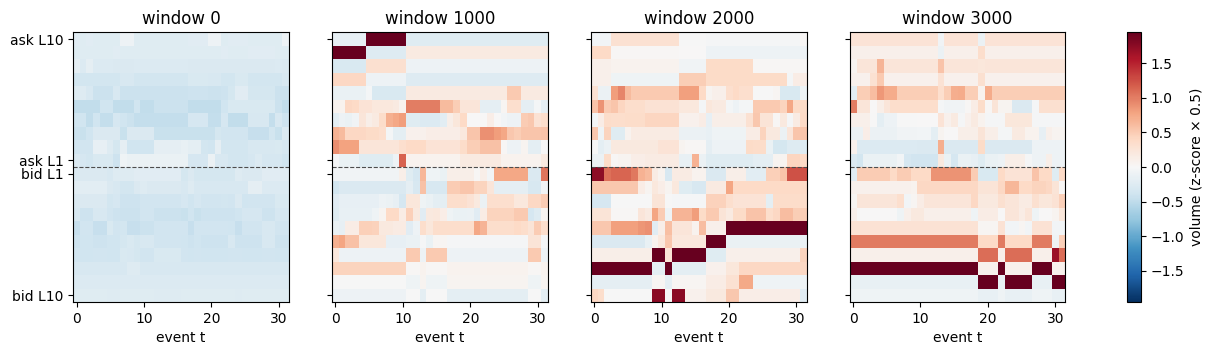

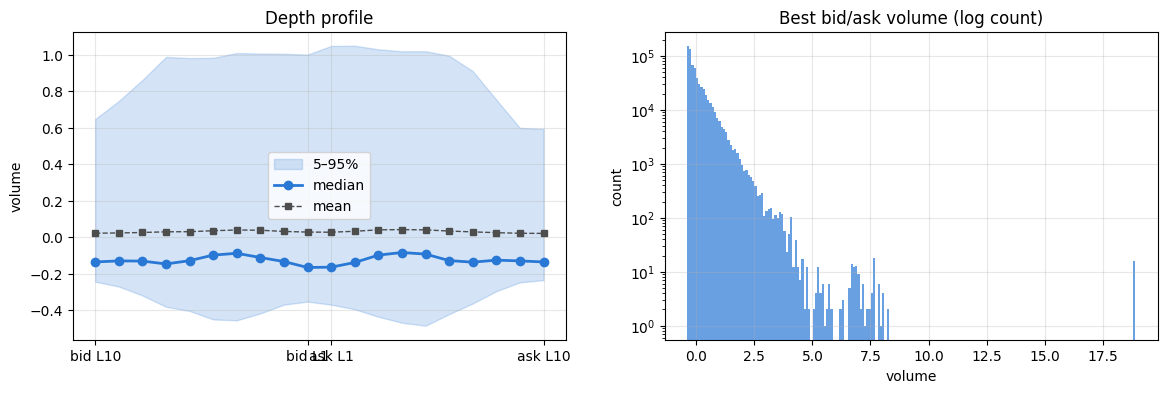

In [4]:
def show_field(ax, field, title, vmax):
    im = ax.imshow(field.T, origin="lower", aspect="auto", cmap=FIELD_CMAP, vmin=-vmax, vmax=vmax,
                   extent=[-0.5, CFG["dim_t"] - 0.5, -0.5, CFG["dim_x"] - 0.5])
    ax.axhline(9.5, color="0.3", lw=0.8, ls="--")   # bid | ask
    ax.set(title=title, xlabel="event t", yticks=LEVEL_TICKS[0], yticklabels=LEVEL_TICKS[1])
    return im

vmax = train_ds.fields.abs().quantile(0.99).item()   # volumes are heavy-tailed: clip the colour range
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5), sharey=True)
for i, ax in enumerate(axes):
    im = show_field(ax, train_ds.fields[i * 1000].numpy(), f"window {i * 1000}", vmax)
fig.colorbar(im, ax=axes, label="volume (z-score × 0.5)")
plt.show()

# Depth profile: mean and spread of volume per level (all events), and the heavy tails
vol = train_ds.fields.flatten(0, 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
q = vol.quantile(torch.tensor([0.05, 0.5, 0.95]), dim=0)
axes[0].fill_between(levels, q[0], q[2], color=REAL_C, alpha=0.2, label="5–95%")
axes[0].plot(levels, q[1], "o-", color=REAL_C, lw=2, label="median")
axes[0].plot(levels, vol.mean(0), "s--", color="0.3", ms=4, lw=1, label="mean")
axes[0].set(xticks=LEVEL_TICKS[0], xticklabels=LEVEL_TICKS[1], ylabel="volume", title="Depth profile")
axes[1].hist(vol[:, [9, 10]].flatten().numpy(), bins=200, color=REAL_C, alpha=0.7, log=True)
axes[1].set(xlabel="volume", ylabel="count", title="Best bid/ask volume (log count)")
for ax in axes: ax.grid(alpha=0.3)
axes[0].legend(); plt.show()

## Signature kernel sanity check

Should converge to `I_0(2 sqrt(ab))` as `dyadic_order` grows.

In [5]:
from scipy.special import i0
a, b = 0.7, 1.3
X = torch.linspace(0, a, 5, dtype=torch.float64)[None, :, None]
Y = torch.linspace(0, b, 7, dtype=torch.float64)[None, :, None]
for o in range(5):
    k = SigKernel("linear", dyadic_order=o)(X, Y).item()
    print(f"dyadic_order={o}:  k_sig={k:.8f}   exact={i0(2*np.sqrt(a*b)):.8f}   err={abs(k - i0(2*np.sqrt(a*b))):.2e}")

dyadic_order=0:  k_sig=2.13998678   exact=2.13919252   err=7.94e-04
dyadic_order=1:  k_sig=2.13944062   exact=2.13919252   err=2.48e-04
dyadic_order=2:  k_sig=2.13926050   exact=2.13919252   err=6.80e-05
dyadic_order=3:  k_sig=2.13921024   exact=2.13919252   err=1.77e-05
dyadic_order=4:  k_sig=2.13919704   exact=2.13919252   err=4.52e-06


## Model

NeuralSPDEGenerator(
  (noise): QWienerNoise()
  (lift): Linear(in_features=1, out_features=16, bias=True)
  (func): LocalOperators(
    (F): Sequential(
      (0): Conv2d(16, 16, kernel_size=(1, 1), stride=(1, 1))
      (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): Tanh()
    )
    (G): Sequential(
      (0): Conv2d(16, 32, kernel_size=(1, 1), stride=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): Tanh()
    )
  )
  (conv): KernelConvolution()
  (readout): Sequential(
    (0): Linear(in_features=16, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=1, bias=True)
  )
)
Parameters: 54.4 K


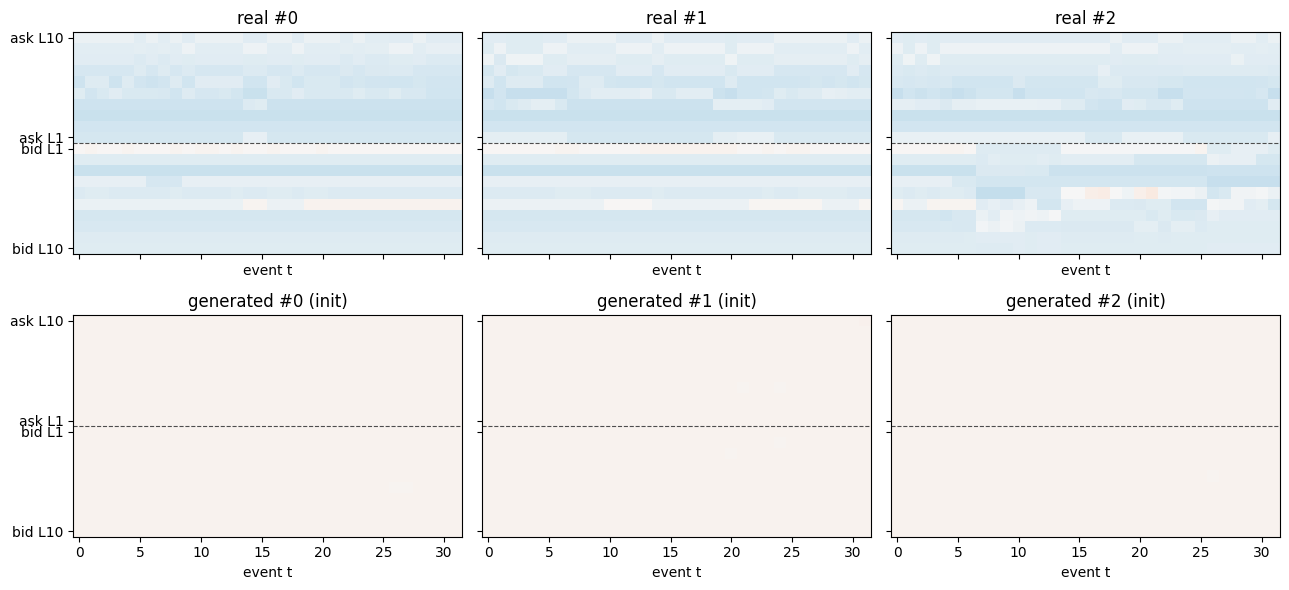

In [6]:
generator = build_generator(CFG).to(CFG["device"])
print(generator)
print(f"Parameters: {sum(p.numel() for p in generator.parameters()) / 1e3:.1f} K")

# Generator at initialisation, from the same u0s as real samples
real = test_ds.fields[:CFG["batch_size"]]
fake = generate(generator, real[:, 0], ts)
fig, axes = plt.subplots(2, 3, figsize=(13, 6), sharex=True, sharey=True)
for i in range(3):
    show_field(axes[0, i], real[i].numpy(), f"real #{i}", vmax)
    show_field(axes[1, i], fake[i].numpy(), f"generated #{i} (init)", vmax)
plt.tight_layout(); plt.show()

## Train

Real-vs-real level below is the target loss.

In [7]:
if CFG["wandb_log"]:
    wandb.init(project=CFG["wandb_project"], entity=CFG["wandb_entity"], config=CFG)

with torch.no_grad():
    kernel = build_kernel(CFG)
    r1, r2 = (score_transform(test_ds.fields[i*128:(i+1)*128].to(CFG["device"]), CFG["alpha"]) for i in (0, 1))
    real_floor = signature_kernel_score(kernel, r1, r2).item()
print(f"real-vs-real score (target level): {real_floor:.4f}")

real-vs-real score (target level): -8.4671


In [8]:
if CFG["mode"] in ("train", "resume"):
    generator, avg_generator, loss_history, test_loss_history = train(CFG, train_loader, test_loader)

  Parameters : 54.4 K
Step   250/3000  |  loss=-2.10579  grad_norm=3.388  test_loss=-2.70824
Step   500/3000  |  loss=-2.32471  grad_norm=11.529  test_loss=-2.88012
Step   750/3000  |  loss=-2.35183  grad_norm=6.866  test_loss=-2.38092
Step  1000/3000  |  loss=-2.37266  grad_norm=6.011  test_loss=-2.35284
  -> saved checkpoints/lob/ckpt2026-10-21_19-05_step001000.pt
Step  1250/3000  |  loss=-2.39746  grad_norm=8.261  test_loss=-2.33383
Step  1500/3000  |  loss=-2.43104  grad_norm=5.626  test_loss=-2.17686
Step  1750/3000  |  loss=-2.45889  grad_norm=7.784  test_loss=-2.14381
Step  2000/3000  |  loss=-2.45758  grad_norm=4.289  test_loss=-2.06853
  -> saved checkpoints/lob/ckpt2026-10-21_19-10_step002000.pt
Step  2250/3000  |  loss=-2.47875  grad_norm=12.349  test_loss=-2.05823
Step  2500/3000  |  loss=-2.49154  grad_norm=5.682  test_loss=-1.99215
Step  2750/3000  |  loss=-2.48175  grad_norm=6.861  test_loss=-1.94117
Step  3000/3000  |  loss=-2.50483  grad_norm=9.151  test_loss=-1.89564


## Load pretrained model

In [9]:
# Latest checkpoint in CFG["ckpt_dir"], with SWA-averaged weights and loss histories
generator, loaded_cfg, loss_history, test_loss_history = load_checkpoint(CFG, averaged=True)

Loading checkpoints/lob/ckpt2026-10-21_19-16_step003000.pt  (step 3000)


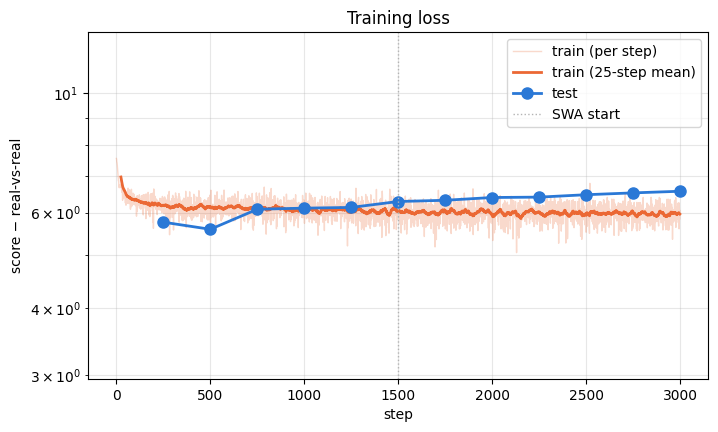

In [10]:
# Excess score over the real-vs-real level (~ MMD^2), on a log scale; per-step values
# below the floor cannot be shown and are masked
fig, ax = plt.subplots(figsize=(8, 4.5))
w = 25
pos    = lambda a: np.where(a > 0, a, np.nan)
excess = np.asarray(loss_history) - real_floor
smooth = np.convolve(excess, np.ones(w) / w, mode="valid")
ax.plot(pos(excess), color=GEN_C, alpha=0.25, lw=1, label="train (per step)")
ax.plot(np.arange(w - 1, len(excess)), pos(smooth), color=GEN_C, lw=2, label=f"train ({w}-step mean)")
shown = [smooth]
if test_loss_history:
    s, l = zip(*test_loss_history)
    l = np.asarray(l) - real_floor
    ax.plot(s, pos(l), "o-", color=REAL_C, ms=8, lw=2, label="test")
    shown.append(l)
ax.axvline(loaded_cfg["swa_step_start"], color="0.7", ls=":", lw=1, label="SWA start")
# y-range: 1st-99th percentile of the smoothed and test curves, ignoring early spikes
v = np.concatenate(shown); v = v[v > 0]
lo, hi = np.percentile(v, [1, 99])
ax.set_yscale("log"); ax.set_ylim(lo / 2, hi * 2)
ax.set(xlabel="step", ylabel="score − real-vs-real", title="Training loss")
ax.legend(); ax.grid(alpha=0.3, which="both"); plt.show()

## Evaluation

1. Population: generated vs test fields.
2. KS on every (t, x) marginal: 100 runs of 128 vs 128.

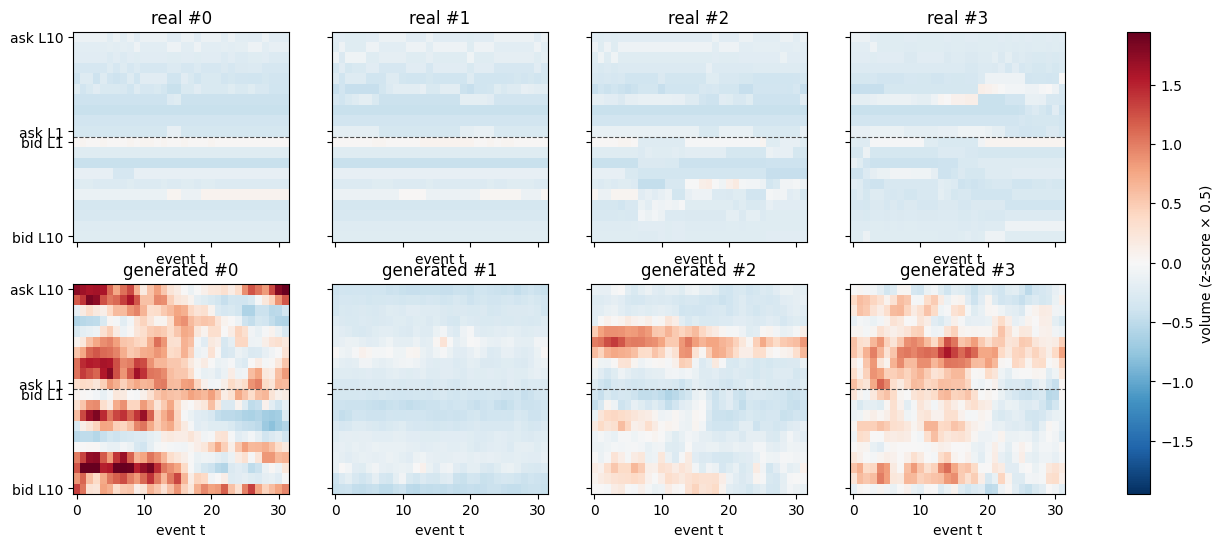

score generated vs test: -1.9493 ± 0.1483   (real-vs-real: -8.4671)


In [11]:
real_pop = test_ds.fields
fake_pop = generate(generator, real_pop[:, 0], ts)

# Side by side: real vs generated from the same u0
fig, axes = plt.subplots(2, 4, figsize=(16, 6), sharex=True, sharey=True)
for i in range(4):
    show_field(axes[0, i], real_pop[i].numpy(), f"real #{i}", vmax)
    im = show_field(axes[1, i], fake_pop[i].numpy(), f"generated #{i}", vmax)
fig.colorbar(im, ax=axes, label="volume (z-score × 0.5)")
plt.show()

# Final score on held-out data vs the real-vs-real level
with torch.no_grad():
    kernel = build_kernel(loaded_cfg)
    gen_scores = []
    for i in range(4):
        y = real_pop[i*128:(i+1)*128].to(CFG["device"])
        gen_scores.append(signature_kernel_score(kernel, score_transform(fake_pop[i*128:(i+1)*128].to(CFG["device"]), CFG["alpha"]),
                                                 score_transform(y, CFG["alpha"])).item())
print(f"score generated vs test: {np.mean(gen_scores):.4f} ± {np.std(gen_scores):.4f}   (real-vs-real: {real_floor:.4f})")

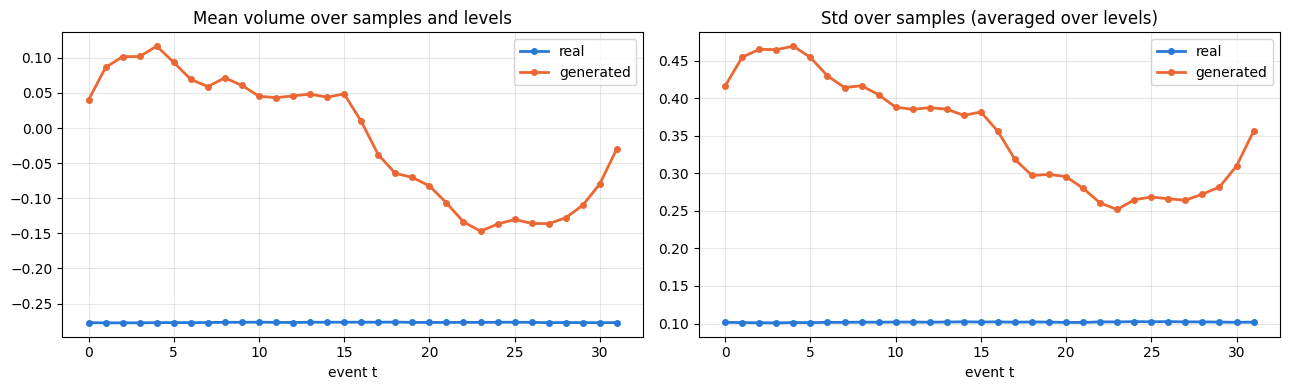

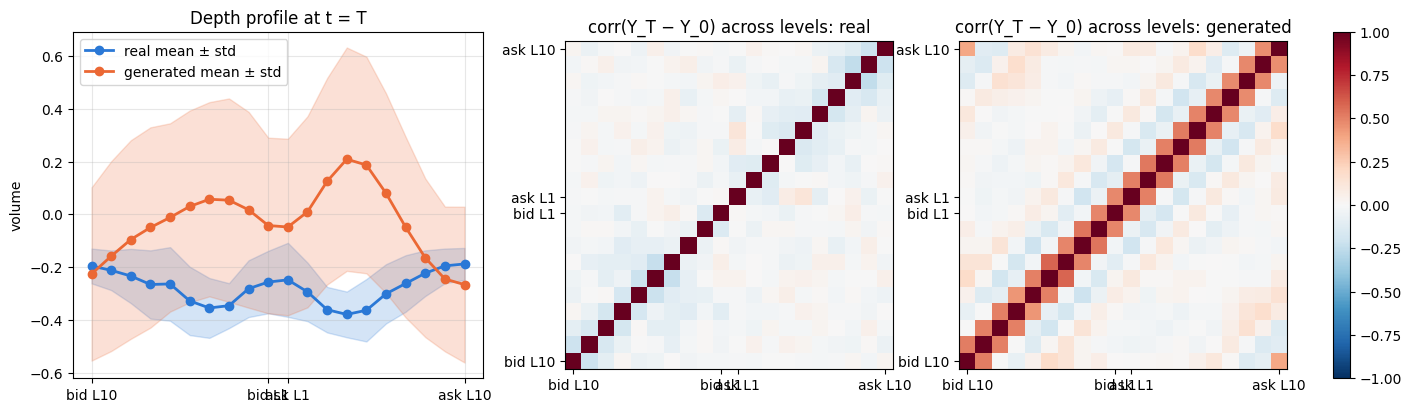

In [12]:
# Population statistics over time: mean and std of Y(t, .) averaged over levels
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
t_np = np.arange(CFG["dim_t"])
for arr, c, lab in [(real_pop, REAL_C, "real"), (fake_pop, GEN_C, "generated")]:
    axes[0].plot(t_np, arr.mean(dim=(0, 2)), "o-", color=c, ms=4, lw=2, label=lab)
    axes[1].plot(t_np, arr.std(dim=0).mean(dim=1), "o-", color=c, ms=4, lw=2, label=lab)
axes[0].set(title="Mean volume over samples and levels", xlabel="event t")
axes[1].set(title="Std over samples (averaged over levels)", xlabel="event t")
for ax in axes: ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

# Depth profile at t = T, and correlation across levels of the volume change Y_T - Y_0
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for arr, c, lab in [(real_pop, REAL_C, "real"), (fake_pop, GEN_C, "generated")]:
    m, s = arr[:, -1].mean(0), arr[:, -1].std(0)
    axes[0].fill_between(levels, m - s, m + s, color=c, alpha=0.2)
    axes[0].plot(levels, m, "o-", color=c, lw=2, label=f"{lab} mean ± std")
axes[0].set(xticks=LEVEL_TICKS[0], xticklabels=LEVEL_TICKS[1], ylabel="volume", title="Depth profile at t = T")
axes[0].legend(); axes[0].grid(alpha=0.3)
for ax, arr, lab in [(axes[1], real_pop, "real"), (axes[2], fake_pop, "generated")]:
    C = np.corrcoef((arr[:, -1] - arr[:, 0]).numpy().T)
    im = ax.imshow(C, origin="lower", cmap=FIELD_CMAP, vmin=-1, vmax=1)
    ax.set(title=f"corr(Y_T − Y_0) across levels: {lab}",
           xticks=LEVEL_TICKS[0], xticklabels=LEVEL_TICKS[1], yticks=LEVEL_TICKS[0], yticklabels=LEVEL_TICKS[1])
fig.colorbar(im, ax=axes[1:]); plt.show()

average KS statistic 0.5712  |  rejected at 5%: 100.0% of (run, t, x)


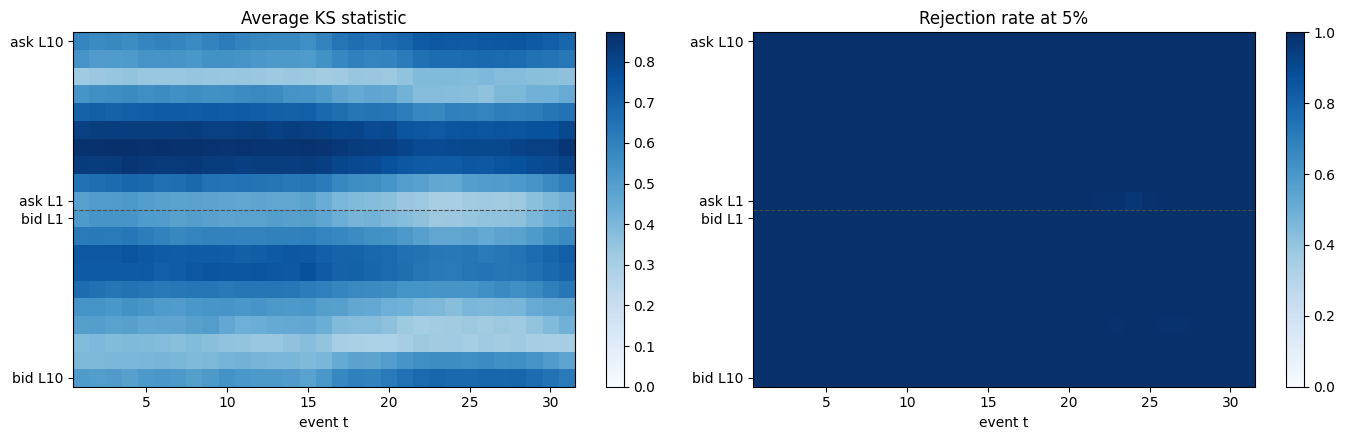

In [13]:
# KS test on every (t, x) marginal, 100 runs of 128 vs 128 (paper Fig. 3); t = 0 is the given u0
n_runs, n_ks = 100, 128
ks_stat = np.zeros((n_runs, CFG["dim_t"] - 1, CFG["dim_x"]))
ks_p    = np.zeros_like(ks_stat)
for r in range(n_runs):
    idx    = torch.randperm(len(test_ds))[:n_ks]
    real_r = test_ds.fields[idx]
    fake_r = generate(generator, real_r[:, 0], ts)
    res    = ks_2samp(fake_r[:, 1:].numpy(), real_r[:, 1:].numpy(), axis=0)
    ks_stat[r], ks_p[r] = res.statistic, res.pvalue

mean_ks = ks_stat.mean(0)
reject  = (ks_p <= 0.05).mean(0)
print(f"average KS statistic {mean_ks.mean():.4f}  |  rejected at 5%: {reject.mean():.1%} of (run, t, x)")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, M, title, vmax_ in [(axes[0], mean_ks, "Average KS statistic", None),
                            (axes[1], reject, "Rejection rate at 5%", 1)]:
    im = ax.imshow(M.T, origin="lower", aspect="auto", cmap="Blues", vmin=0, vmax=vmax_,
                   extent=[0.5, CFG["dim_t"] - 0.5, -0.5, CFG["dim_x"] - 0.5])
    ax.axhline(9.5, color="0.3", lw=0.8, ls="--")
    ax.set(title=title, xlabel="event t", yticks=LEVEL_TICKS[0], yticklabels=LEVEL_TICKS[1])
    fig.colorbar(im, ax=ax)
plt.tight_layout(); plt.show()

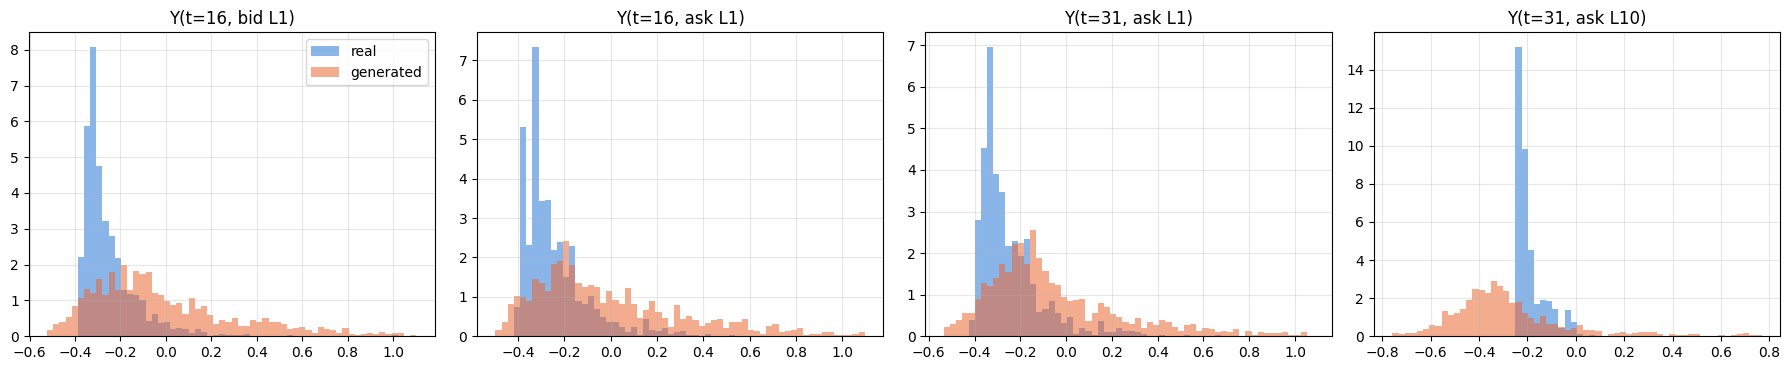

In [14]:
# Marginals at a few (t, x) points, pooled over the test windows
pts = [(CFG["dim_t"] // 2, 9), (CFG["dim_t"] // 2, 10), (CFG["dim_t"] - 1, 10), (CFG["dim_t"] - 1, 19)]
names = {9: "bid L1", 10: "ask L1", 19: "ask L10"}
fig, axes = plt.subplots(1, len(pts), figsize=(4.5 * len(pts), 3.8))
for ax, (ti, xi) in zip(axes, pts):
    r_, f_ = real_pop[:, ti, xi].numpy(), fake_pop[:, ti, xi].numpy()
    bins = np.histogram_bin_edges(np.concatenate([r_, f_]), bins=60, range=np.percentile(np.concatenate([r_, f_]), [0.5, 99.5]))
    ax.hist(r_, bins=bins, density=True, color=REAL_C, alpha=0.55, label="real")
    ax.hist(f_, bins=bins, density=True, color=GEN_C, alpha=0.55, label="generated")
    ax.set(title=f"Y(t={ti}, {names[xi]})"); ax.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout(); plt.show()

In [ ]:
if wandb.run is not None:   
    wandb.finish()